# Part 2: Indexing and Evaluation

This notebook contains all the code and results of Part 2. The Part 1 pre-processing (`../part_1/preprocessing.py`) is
imported **without any change**, so documents and queries go through exactly the same steps as in Part 1.
The new code is in three small modules of this folder:

| Module | Content |
|---|---|
| `indexing.py` | inverted index, conjunctive (AND) retrieval, TF-IDF (cosine) ranking, BM25 (only for the analysis) |
| `evaluation.py` | P@K, R@K, F1@K, AP@K, MAP, MRR, NDCG@K |
| `judgments.py` | our relevance guidelines for the five test queries, applied by code so that every label has a reason |
| `test_part2.py` | tests of the metrics (hand-computed values, scikit-learn) and of the index / TF-IDF (brute force) |

Structure:
1. Setup and loading
2. **Part 1 – Indexing**: inverted index, test queries, TF-IDF ranking
3. **Part 2 – Evaluation**: metrics, validation queries, our relevance judgments, results, analysis and limitations

## 1. Setup and loading

In [9]:
import os, sys, re, time, json, math, warnings
from collections import Counter
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

warnings.filterwarnings("ignore")

# the notebook lives in project_progress/part_2, the repo root is two levels up
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
PART1 = os.path.join(ROOT, "project_progress", "part_1")
sys.path.insert(0, os.getcwd())
sys.path.insert(0, PART1)                      # Part 1 code
DATA_PATH = os.path.join(ROOT, "data", "fashion_products_dataset.json")
LABELS_PATH = os.path.join(ROOT, "data", "validation_labels.csv")
CORPUS_PATH = os.path.join(ROOT, "data", "processed_corpus.pkl")   # Written by the Part 1 notebook
FIG_DIR = os.path.join(os.getcwd(), "figures")
RES_DIR = os.path.join(os.getcwd(), "results")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

try:
    nltk.corpus.stopwords.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)

import preprocessing as pp  # From Part 1
from indexing import InvertedIndex, TfidfRanker, Bm25Ranker, SearchEngine
from evaluation import (condense, evaluate_query, evaluate_run, relevant_set, interpolated_pr_curve)
import judgments as J

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_columns", 40)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

In [10]:
raw = pd.read_json(DATA_PATH)
labels = pd.read_csv(LABELS_PATH)
if os.path.exists(CORPUS_PATH):
    corpus = pd.read_pickle(CORPUS_PATH)   # Part 1 output
else:
    corpus = pp.preprocess_corpus(raw) 
    corpus.to_pickle(CORPUS_PATH)
terms_all = [t for toks in corpus.all_terms for t in toks]
print("documents:", len(corpus), "| validation labels:", len(labels))
print("consistency with the Part 1 report -> total terms:", f"{len(terms_all):,}",
      "| vocabulary:", f"{len(set(terms_all)):,}", "(Part 1 reported 1.26M terms and 5,865 terms)")
assert len(set(terms_all)) == 5865

documents: 28080 | validation labels: 40
consistency with the Part 1 report -> total terms: 1,256,332 | vocabulary: 5,865 (Part 1 reported 1.26M terms and 5,865 terms)


# 2. Part 1 – Indexing

## 2.1 Inverted index

**Decision: the index is built on `all_terms`**, the merged field of Part 1 (title + description + brand + sub_category +
product_details values), which is the field that Part 1 reserved for the basic TF-IDF index of Part 2. The other term lists
(`title_terms`, `product_details_terms`, ...) stay available for the field-weighted experiments of section 3.6.

Structure (the vocabulary of the practical labs, with term frequencies added): every term has a numeric id and
`postings[term_id] = [(doc_id, tf), ...]` sorted by `doc_id`. Keeping the postings sorted lets us intersect two lists with a
linear merge, and storing `tf` lets TF-IDF be computed from the index alone, without reading the documents again.

In [11]:
t0 = time.time()
index = InvertedIndex(corpus.pid.tolist(), corpus.all_terms.tolist())
build_time = time.time() - t0
lengths = np.array([len(p) for p in index.postings.values()])
index_stats = pd.Series({
    "documents (N)": index.num_docs,
    "vocabulary (terms)": index.vocabulary_size,
    "postings (term-document pairs)": int(lengths.sum()),
    "average postings list length": round(lengths.mean(), 1),
    "longest postings list": int(lengths.max()),
    "terms in only one document": int((lengths == 1).sum()),
    "average document length (terms)": round(np.mean(index.doc_length), 1),
    "build time (s)": round(build_time, 2),
}, dtype=object)
print(index_stats.to_string())

documents (N)                       28080
vocabulary (terms)                   5865
postings (term-document pairs)     875911
average postings list length        149.3
longest postings list               20987
terms in only one document           1332
average document length (terms)      44.7
build time (s)                       1.61


In [12]:
# The structure of the lab hint: term -> list of documents (first 4 documents shown)
for term in ["sweatshirt", "jean", "cotton"]:
    term_id = index.term_to_id[term]
    docs = [index.pids[d] for d, tf in index.postings[term_id]]
    print(f"term_id {term_id:>4} ({term!r}, df={len(docs):,}): {docs[:4]} ...")
print()
print("postings of 'sweatshirt' with tf:", index.get_postings("sweatshirt")[:5], "...")

term_id 1096 ('sweatshirt', df=1,420): ['SWSFYD33P2XCBWFG', 'SWSFYD3KMGTBZEJZ', 'SWSFYD38Y2MAT9FQ', 'SWSFVEV2YFEJKUCK'] ...
term_id  685 ('jean', df=2,436): ['TSHFHJKSY8FNR7PV', 'TSHFHJKRPYSHNEMG', 'TSHFHJKR4AF3G9KY', 'TSHFHJKR4CAKQVC5'] ...
term_id   11 ('cotton', df=19,905): ['TKPFCZ9EA7H5FYZH', 'TKPFCZ9EJZV2UVRZ', 'TKPFCZ9EHFCY5Z4Y', 'TKPFCZ9ESZZ7YWEF'] ...

postings of 'sweatshirt' with tf: [(1215, 1), (1216, 1), (1217, 1), (1562, 2), (1563, 1)] ...


## 2.2 Conjunctive (AND) queries

A document is returned only if it contains **all** the query terms. The query goes through the same `preprocess_text` as the
documents. The postings lists are intersected from the shortest (rarest term) to the longest. A query term that is not in
the vocabulary makes the result empty. We check the intersection against a brute-force scan of the whole collection.

In [13]:
VALIDATION_QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}   # given in the statement
TEST_QUERIES = J.QUERIES                                                                    # our five queries (T1..T5)

engine = SearchEngine(index, pp.preprocess_text)             # AND + cosine TF-IDF

# brute-force check of the AND semantics for the 7 queries
for text in list(VALIDATION_QUERIES.values()) + list(TEST_QUERIES.values()):
    terms = pp.preprocess_text(text)
    brute = [i for i, doc_terms in enumerate(corpus.all_terms) if set(terms) <= set(doc_terms)]
    assert index.conjunctive(terms) == brute
print("AND retrieval == brute force for the 7 queries")
print("unknown term ->", index.conjunctive(pp.preprocess_text("women sweatshirt zzzz")), "(empty)")

AND retrieval == brute force for the 7 queries
unknown term -> [] (empty)


## 2.3 Test queries

**How we chose them.** The hint suggests popular terms. We ranked all the terms by the total TF-IDF weight they carry in the
collection (sum over the documents of `(1 + log tf) * idf`; a term gets a large value when it is frequent but still
discriminative) and by document frequency in the titles:

In [14]:
N = index.num_docs
mass = Counter()
for term, term_id in index.term_to_id.items():
    idf = index.idf(term)
    for doc_id, tf in index.postings[term_id]:
        mass[term] += (1 + math.log10(tf)) * idf
title_df = Counter(t for terms in corpus.title_terms for t in set(terms))
top_terms = pd.DataFrame({
    "rank": range(1, 21),
    "term": [t for t, _ in mass.most_common(20)],
    "tf-idf mass": [round(m) for _, m in mass.most_common(20)],
    "df (all_terms)": [index.document_frequency(t) for t, _ in mass.most_common(20)],
    "df (title)": [title_df[t] for t, _ in mass.most_common(20)],
})
top_terms.to_csv(os.path.join(RES_DIR, "top_terms_tfidf.csv"), index=False)
print(top_terms.T.to_string(header=False))

rank                1      2       3      4      5      6      7        8     9     10     11      12     13    14    15       16    17    18      19     20
term            round  print  tshirt   neck  solid  women    men  regular  blue    fit  shirt  casual  black  slim  full  comfort  half  polo  fabric  blend
tf-idf mass      6472   6008    5981   5913   5557   5363   5238     5148  5133   4938   4927    4924   4924  4918  4882     4724  4680  4478    4456   4438
df (all_terms)   9551   9563   13063  14585  12031  13826  14251    13292  7709  10979   4813    9733   6313  5680  7177     7328  8576  3051    5725  13594
df (title)       8301   8106   12248  11952   9215  13041  13021     1754  4282   3923   3591    2927   3501  2828  2011       16    26  2668     536   1063


The most weighted terms are gender (`men`, `women`), product types (`tshirt`, `shirt`), attributes (`round`, `neck`, `solid`,
`print`, `black`, `blue`, `slim`, `full`) and a few more specific types (`polo`, `sweatshirt`, `jacket`, `jean`).
The five queries combine popular terms of different kinds and each one is built to show a different behaviour of the system.
Because of the relevance judgments of section 3.3 we also wanted queries whose relevant documents can be defined from the
visible attributes of the product.

In [15]:
PURPOSE = {
    1: "attribute combination with popular terms (colour, fabric, product type)",
    2: "V neck: the 1-character token 'v' is removed by the Part 1 pre-processing",
    3: "stemming and indexed values: 'hooded' / 'Hooded: Yes'",
    4: "'shirt' vs 'tshirt' and other products that mention shirts in their text",
    5: "a fabric that is also a product type ('denim' appears in jeans, shirts, jackets)",
}
rows = []
for qid, text in TEST_QUERIES.items():
    terms = pp.preprocess_text(text)
    rows.append({"id": f"T{qid}", "query": text, "terms after pre-processing": " ".join(terms),
                 "df of each term": ", ".join(str(index.document_frequency(t)) for t in terms),
                 "AND matches": len(index.conjunctive(terms)), "what it tests": PURPOSE[qid]})
test_query_table = pd.DataFrame(rows)
test_query_table.to_csv(os.path.join(RES_DIR, "test_queries.csv"), index=False)
test_query_table

,id,query,terms after pre-processing,df of each term,AND matches,what it tests
0,T1,men black track pants polyester,men black track pant polyest,"14251, 6313, 1815, 2028, 3033",79,"attribute combination with popular terms (colour, fabric, product ..."
1,T2,women black v neck tshirt,women black neck tshirt,"13826, 6313, 14585, 13063",1584,V neck: the 1-character token 'v' is removed by the Part 1 pre-pro...
2,T3,men grey hooded sweatshirt,men grey hood sweatshirt,"14251, 3046, 920, 1420",40,stemming and indexed values: 'hooded' / 'Hooded: Yes'
3,T4,women striped shirt,women stripe shirt,"13826, 1464, 4813",114,'shirt' vs 'tshirt' and other products that mention shirts in thei...
4,T5,men denim jacket,men denim jacket,"14251, 1778, 1097",73,"a fabric that is also a product type ('denim' appears in jeans, sh..."


## 2.4 TF-IDF ranking

The documents that satisfy the AND condition are ranked by cosine similarity in the vector space model:

$$w_{t,d} = (1 + \log_{2} tf_{t,d}) \cdot \log_{2}\frac{N}{df_t}, \qquad
\text{score}(q,d) = \frac{\sum_t w_{t,q}\, w_{t,d}}{\lVert q \rVert \; \lVert d \rVert}$$

`w_{t,q}` uses the same weighting with the query term frequency. The norm `||d||` is computed over **all** the terms of the
document (precomputed when the ranker is created), and ties are broken by document id so that the ranking is deterministic.
`indexing.py` is checked in `test_part2.py` against a dense NumPy implementation on random corpora.

In [16]:
def show_top(text, k=5):
    res = engine.search(text, top_k=k)
    return pd.DataFrame([{"rank": i, "score": round(s, 3), "pid": pid, "title": corpus.loc[pid, "title"],
                          "brand": corpus.loc[pid, "brand"]} for i, (pid, s) in enumerate(res, 1)])

top_rows = []
for name, text in [(f"Q{q}", t) for q, t in VALIDATION_QUERIES.items()] + [(f"T{q}", t) for q, t in TEST_QUERIES.items()]:
    res = engine.search(text, top_k=10)
    for rank, (pid, score) in enumerate(res, 1):
        top_rows.append({"query": name, "text": text, "rank": rank, "score": round(score, 4), "pid": pid,
                         "title": corpus.loc[pid, "title"], "brand": corpus.loc[pid, "brand"]})
pd.DataFrame(top_rows).to_csv(os.path.join(RES_DIR, "top10_results.csv"), index=False)
print("T1:", TEST_QUERIES[1]); display(show_top(TEST_QUERIES[1]))
print("T4:", TEST_QUERIES[4]); display(show_top(TEST_QUERIES[4]))

T1: men black track pants polyester


,rank,score,pid,title,brand
0,1,0.924,TKPFZMZSWZN5HKEZ,Solid Men Black Track Pants,None
1,2,0.681,TKPFWCVUMWW96BEY,Solid Men Black Track Pants,Breakboun
2,3,0.655,TKPFZDVZVQHWEUVF,Solid Men Black Track Pants,Onei
3,4,0.651,TKPFPT6HZFHXZ4TN,Solid Men Black Track Pants,Pu
4,5,0.630,TKPFZ3JRTTXYMHFN,Solid Men Black Track Pants,REEB


T4: women striped shirt


,rank,score,pid,title,brand
0,1,0.635,SHTFSYCUNEAUZFTG,Women Slim Fit Striped Casual Shirt,True Bl
1,2,0.625,SHTFWP8CDRGUQTBP,Women Regular Fit Striped Casual Shirt,Mett
2,3,0.625,SHTFWP8C4QRRU2GA,Women Regular Fit Striped Casual Shirt,Mett
3,4,0.605,SHTFWP8CK8GAUWFA,Women Regular Fit Striped Casual Shirt,Mett
4,5,0.605,SHTFWP8CYSMGNH5T,Women Regular Fit Striped Casual Shirt,Mett


# 3. Part 2 – Evaluation

## 3.1 Evaluation metrics

All of them are in `evaluation.py`. A ranking is a list of pids (best first); the judgments of a query are `{pid: label}`
with binary labels, and a document without judgment is not relevant. `R` is the number of relevant documents of the query.

| Metric | Definition |
|---|---|
| P@K | relevant documents in the first K positions / K (if there are fewer than K results the missing positions count as misses) |
| R@K | relevant documents in the first K positions / R |
| F1@K | harmonic mean of P@K and R@K |
| AP@K | (1 / min(K, R)) * sum over the first K positions of P@i * rel_i. With no cut-off the denominator is R: this is the classic Average Precision |
| MAP | mean over the queries of the Average Precision |
| MRR | mean over the queries of the reciprocal rank 1 / (position of the first relevant document) |
| NDCG@K | DCG@K / IDCG@K with DCG@K = sum_i rel_i / log2(i + 1), and IDCG@K the DCG@K of the ideal ranking |

The tests check these definitions against values computed by hand and against scikit-learn (`ndcg_score`,
`average_precision_score`), and the index and TF-IDF against brute-force implementations:

In [18]:
import test_part2 as T
for name in sorted(n for n in dir(T) if n.startswith("test_")):
    getattr(T, name)()
    print("ok", name)

ok test_against_scikit_learn_if_available
ok test_average_precision_and_rr
ok test_bm25_matches_brute_force
ok test_condense_keeps_order
ok test_interpolated_pr_curve
ok test_map_and_mrr_are_means_over_queries
ok test_min_match_is_a_soft_and
ok test_ndcg
ok test_perfect_and_empty_rankings
ok test_precision_recall_f1
ok test_random_corpora_match_brute_force
ok test_toy_corpus


## 3.2 Validation queries (`validation_labels.csv`)

The file has 20 judged documents for each of the two queries (13 and 10 of them relevant). The collection has 28,080 documents,
so only a small sample is judged and we have to decide how to compare our ranking with it.

**Protocol (used for the reported numbers).** The system returns the AND results ranked by TF-IDF. We keep, in the same order,
only the judged documents that the system returns (the *condensed list* of Sakai, 2007), because a document without judgment is
not a non-relevant document: it was just never judged. The judged documents that the system does **not** return stay in `R`, so
the loss of the AND semantics is counted in the recall-oriented metrics. Sections 3.2.1 and 3.5 show what happens with the two
other possible protocols.

In [19]:
qrels_val = {q: dict(zip(g.pid, g.labels)) for q, g in labels.groupby("query_id")}
KS = (5, 10, 20)

full_run_val = {q: [pid for pid, _ in engine.search(text)] for q, text in VALIDATION_QUERIES.items()}   # whole AND ranking
run_val = {q: condense(full_run_val[q], qrels_val[q]) for q in VALIDATION_QUERIES}                       # condensed list

coverage = pd.DataFrame({
    "AND matches": {q: len(full_run_val[q]) for q in VALIDATION_QUERIES},
    "judged": {q: len(qrels_val[q]) for q in VALIDATION_QUERIES},
    "judged and returned": {q: len(run_val[q]) for q in VALIDATION_QUERIES},
    "relevant (R)": {q: sum(qrels_val[q].values()) for q in VALIDATION_QUERIES},
    "relevant and returned": {q: sum(qrels_val[q][p] for p in run_val[q]) for q in VALIDATION_QUERIES},
})
coverage.index.name = "query"
coverage

,AND matches,judged,judged and returned,relevant (R),relevant and returned
query,,,,,
1,496,20,20,13,13
2,224,20,8,10,6


In [20]:
def wide(table, ks=KS, metrics=("P", "R", "AP", "F1", "NDCG")):
    out = pd.DataFrame({(q, k): {m: table.loc[q, f"{m}@{k}"] for m in metrics} for q in table.index for k in ks})
    out.columns = pd.MultiIndex.from_tuples([(f"Query {q}" if q != "mean" else "Mean", f"K={k}") for q, k in out.columns])
    out.index = [f"{m}@K" for m in metrics]
    return out

val_table = evaluate_run(run_val, qrels_val, KS)
val_wide = wide(val_table).round(3)
val_global = pd.DataFrame({"AP": val_table["AP"], "RR": val_table["RR"]}).round(3)
val_global.index = ["Query 1", "Query 2", "Mean (MAP / MRR)"]
val_table.round(3).to_csv(os.path.join(RES_DIR, "validation_metrics.csv"))
display(val_wide)
display(val_global)

Query 1               Query 2                 Mean              
           K=5   K=10   K=20     K=5   K=10   K=20    K=5   K=10   K=20
P@K      1.000  1.000  0.650   0.800  0.600  0.300  0.900  0.800  0.475
R@K      0.385  0.769  1.000   0.400  0.600  0.600  0.392  0.685  0.800
AP@K     1.000  1.000  0.950   0.800  0.569  0.569  0.900  0.785  0.760
F1@K     0.556  0.870  0.788   0.533  0.600  0.400  0.544  0.735  0.594
NDCG@K   1.000  1.000  0.988   0.869  0.716  0.716  0.934  0.858  0.852

,AP,RR
Query 1,0.950,1.0
Query 2,0.569,1.0
Mean (MAP / MRR),0.760,1.0


### 3.2.1 The same ranking under the two other protocols (only for the analysis)

In [21]:
# A: strict. The whole ranking is compared with the judgments, a document without judgment counts as non-relevant.
# C: re-ranking of the 20 judged documents with TF-IDF, without the AND filter (documents that the AND removes are kept).
run_A = full_run_val
run_C = {q: [pid for pid, _ in engine.rank_pool(text, list(qrels_val[q]))] for q, text in VALIDATION_QUERIES.items()}
protocols = {}
for name, run in [("A strict (unjudged = non-relevant)", run_A), ("B condensed list (reported)", run_val),
                  ("C re-rank of the judged pool, no AND", run_C)]:
    t = evaluate_run(run, qrels_val, KS)
    protocols[name] = {"MAP": t.loc["mean", "AP"], "MRR": t.loc["mean", "RR"], "P@10": t.loc["mean", "P@10"],
                       "R@20": t.loc["mean", "R@20"], "NDCG@10": t.loc["mean", "NDCG@10"]}
protocol_table = pd.DataFrame(protocols).T.round(3)
evaluate_run(run_A, qrels_val, KS).round(3).to_csv(os.path.join(RES_DIR, "validation_metrics_strict.csv"))
protocol_table.to_csv(os.path.join(RES_DIR, "validation_protocols.csv"))
protocol_table

,MAP,MRR,P@10,R@20,NDCG@10
A strict (unjudged = non-relevant),0.080,0.503,0.05,0.05,0.110
B condensed list (reported),0.760,1.000,0.80,0.80,0.858
"C re-rank of the judged pool, no AND",0.877,1.000,0.85,1.00,0.886


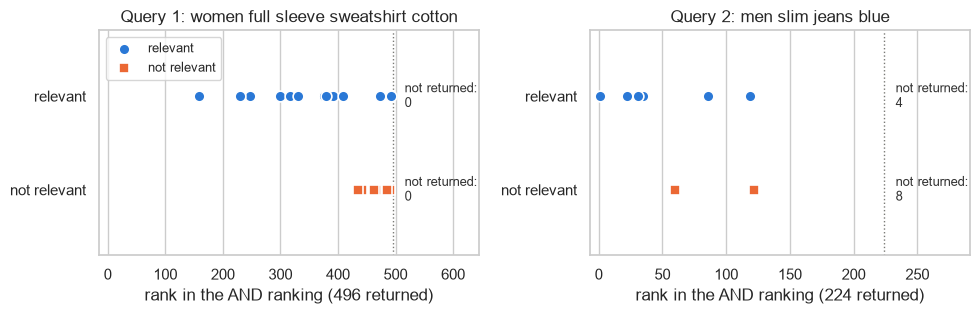

In [22]:
# Where do the judged documents fall in the AND ranking? (Figure 1)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#7a7a76"
for ax, q in zip(axes, VALIDATION_QUERIES):
    ranking = full_run_val[q]
    pos = {pid: i for i, pid in enumerate(ranking, 1)}
    for label, y, color, marker, name in [(1, 1, BLUE, "o", "relevant"), (0, 0, ORANGE, "s", "not relevant")]:
        xs = [pos[p] for p, l in qrels_val[q].items() if l == label and p in pos]
        ax.scatter(xs, [y] * len(xs), s=60, color=color, marker=marker, edgecolor="white", linewidth=1.2, label=name, zorder=3)
        n_missing = sum(1 for p, l in qrels_val[q].items() if l == label and p not in pos)
        ax.text(len(ranking) * 1.04, y, f"not returned:\n{n_missing}", va="center", ha="left", fontsize=9.5, color="#333")
    ax.set(xlim=(-len(ranking) * 0.03, len(ranking) * 1.30), ylim=(-0.7, 1.7), yticks=[0, 1], yticklabels=["not relevant", "relevant"],
           xlabel=f"rank in the AND ranking ({len(ranking)} returned)",
           title=f"Query {q}: {VALIDATION_QUERIES[q]}")
    ax.axvline(len(ranking), color=GREY, lw=1, ls=":")
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", fontsize=9.5, frameon=True)
savefig("validation_judged_documents")

In [23]:
# The judged documents of query 1 are in the bottom third of the ranking: they are LONG documents
len_all = corpus.set_index("pid").all_terms.map(len)
and1 = full_run_val[1]
print("query 1 - mean document length (terms): judged documents %.1f | all AND results %.1f | top-10 results %.1f" % (
    len_all[list(qrels_val[1])].mean(), len_all[and1].mean(), len_all[and1[:10]].mean()))
print("ranks of the 20 judged documents among the %d AND results: %d to %d" % (
    len(and1), min(and1.index(p) + 1 for p in qrels_val[1]), max(and1.index(p) + 1 for p in qrels_val[1])))

query 1 - mean document length (terms): judged documents 72.5 | all AND results 50.0 | top-10 results 20.5
ranks of the 20 judged documents among the 496 AND results: 159 to 492


## 3.3 Our relevance judgments for the five test queries

We act as the expert judges. For every query we wrote **guidelines**: a product is relevant when it satisfies *every*
attribute that the query asks for, judged from what a shopper sees (title and product details), not from the presence of
the stemmed query terms in some field. When title / product details and the free-text description disagree, title and details
win. The guidelines are implemented in `judgments.py` and applied to **all the 28,080 documents** of the collection for each
query, so every document has a label (not only the ones we retrieve), and every label comes with a reason.
After running the rules we read the results: all the documents returned by the AND for T1, T3, T4 and T5, the 43
relevant documents and a sample of the negatives for T2, and every relevant document that the AND does *not* return.
No label needed to be changed (`MANUAL_OVERRIDES` is empty).

In [24]:
for qid, text in TEST_QUERIES.items():
    print(f"T{qid}  {text!r}\n     {J.GUIDELINES[qid]}")

T1  'men black track pants polyester'
     Track pants (not a track suit) for men, black (also if black is one of several colours), made of polyester (blends and polycotton count; cotton-only or cotton blend do not).
T2  'women black v neck tshirt'
     T-shirt with a V neck for women, black (also if black is one of several colours). T-shirts have no Color detail, so the colour is read from the title.
T3  'men grey hooded sweatshirt'
     Sweatshirt for men with a hood, grey (also if grey is one of several colours; sleeveless and half-sleeve hooded sweatshirts count because the query does not ask for sleeves).
T4  'women striped shirt'
     Shirt (not T-shirt, vest, sweater, or unstitched shirt fabric) for women with a striped pattern (also if the pattern list contains other patterns).
T5  'men denim jacket'
     Jacket for men made of denim: 'denim' in the title, in the fabric or in the jacket type (denim blend counts). Other jackets and other denim products (jeans, shirts) do not.


In [25]:
t0 = time.time()
records = corpus.to_dict(orient="records")
judged = {qid: {r["pid"]: J.judge(qid, r) for r in records} for qid in TEST_QUERIES}      # {qid: {pid: (label, reason)}}
print(f"{len(records):,} documents x {len(TEST_QUERIES)} queries judged in {time.time() - t0:.1f} s")

qrels_test = {qid: {pid: lab for pid, (lab, why) in d.items() if lab == 1} for qid, d in judged.items()}   # relevant documents
full_run_test = {qid: [pid for pid, _ in engine.search(text)] for qid, text in TEST_QUERIES.items()}

summary = []
for qid, text in TEST_QUERIES.items():
    rel, ret = set(qrels_test[qid]), set(full_run_test[qid])
    summary.append({"query": f"T{qid}", "text": text, "relevant in the collection (R)": len(rel),
                    "AND matches": len(ret), "relevant and returned": len(rel & ret),
                    "precision of the AND set": round(len(rel & ret) / len(ret), 3),
                    "recall of the AND set": round(len(rel & ret) / len(rel), 3)})
judgment_summary = pd.DataFrame(summary).set_index("query")
judgment_summary.to_csv(os.path.join(RES_DIR, "judgment_summary.csv"))
judgment_summary

28,080 documents x 5 queries judged in 2.4 s


,text,relevant in the collection (R),AND matches,relevant and returned,precision of the AND set,recall of the AND set
query,,,,,,
T1,men black track pants polyester,79,79,68,0.861,0.861
T2,women black v neck tshirt,43,1584,43,0.027,1.000
T3,men grey hooded sweatshirt,48,40,39,0.975,0.812
T4,women striped shirt,74,114,74,0.649,1.000
T5,men denim jacket,38,73,38,0.521,1.000


In [26]:
# Why are the AND results judged not relevant? (reasons grouped, first failed criterion)
reason_rows = []
for qid in TEST_QUERIES:
    for pid in full_run_test[qid]:
        lab, why = judged[qid][pid]
        if lab == 0:
            reason_rows.append({"query": f"T{qid}", "reason": re.sub(r" \(.*\)", "", why)})
reasons = pd.DataFrame(reason_rows).groupby(["query", "reason"]).size().rename("documents").reset_index()
reasons.to_csv(os.path.join(RES_DIR, "judgment_reasons.csv"), index=False)
reasons

,query,reason,documents
0,T1,colour is not black,4
1,T1,fabric is not polyester,4
2,T1,not a track pant,3
3,T2,colour is not black,9
4,T2,not a T-shirt,45
5,T2,not a V neck,1367
6,T2,not for women,120
7,T3,colour is not grey,1
8,T4,not a shirt,31
9,T4,not for women,1


In [27]:
# File with the judgments: every document returned by the AND, plus the relevant documents that the AND does not return.
# Every other document of the collection is not relevant for the query (label 0) and is not listed.
rows = []
for qid, text in TEST_QUERIES.items():
    rank = {pid: i for i, pid in enumerate(full_run_test[qid], 1)}
    listed = list(full_run_test[qid]) + sorted(set(qrels_test[qid]) - set(rank))
    for pid in listed:
        lab, why = judged[qid][pid]
        rows.append({"query_id": f"T{qid}", "query": text, "pid": pid, "title": corpus.loc[pid, "title"], "label": lab,
                     "returned_by_AND": pid in rank, "rank_in_AND_ranking": rank.get(pid), "reason": why})
judgments_df = pd.DataFrame(rows)
judgments_df.to_csv("relevance_judgments.csv", index=False)
print(len(judgments_df), "rows written to relevance_judgments.csv")
print(judgments_df.groupby("query_id").label.agg(["count", "sum"]).rename(columns={"count": "listed", "sum": "relevant"}).T)

1910 rows written to relevance_judgments.csv
query_id  T1    T2  T3   T4  T5
listed    90  1584  49  114  73
relevant  79    43  48   74  38


## 3.4 Results for the five test queries

For these queries the judgments are complete (every document of the collection has a label), so the ranking is the whole AND
ranking and there is no sampling problem: `R` is the number of relevant documents of the whole collection.

In [28]:
test_table = evaluate_run(full_run_test, qrels_test, KS)
test_table.index = [f"T{i}" if i != "mean" else "mean" for i in test_table.index]
test_table.round(3).to_csv(os.path.join(RES_DIR, "test_queries_metrics.csv"))
test_wide = pd.DataFrame({(q, k): {m: test_table.loc[q, f"{m}@{k}"] for m in ("P", "R", "AP", "F1", "NDCG")}
                          for q in test_table.index for k in KS}).round(3)
test_wide.index = [f"{m}@K" for m in ("P", "R", "AP", "F1", "NDCG")]
display(test_wide)
display(test_table[["AP", "RR"]].round(3).T)

T1                   T2                   T3                   T4                   T5                 mean              
           5      10     20     5      10     20     5      10     20     5      10     20     5      10     20     5      10     20
P@K     1.000  1.000  1.000  0.600  0.300  0.150  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  0.920  0.860  0.830
R@K     0.063  0.127  0.253  0.070  0.070  0.070  0.104  0.208  0.417  0.068  0.135  0.270  0.132  0.263  0.526  0.087  0.161  0.307
AP@K    1.000  1.000  1.000  0.483  0.242  0.121  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  0.897  0.848  0.824
F1@K    0.119  0.225  0.404  0.125  0.113  0.095  0.189  0.345  0.588  0.127  0.238  0.426  0.233  0.417  0.690  0.158  0.268  0.441
NDCG@K  1.000  1.000  1.000  0.655  0.425  0.274  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  0.931  0.885  0.855

,T1,T2,T3,T4,T5,mean
AP,0.821,0.106,0.8,0.933,0.953,0.723
RR,1.000,1.000,1.0,1.000,1.000,1.000


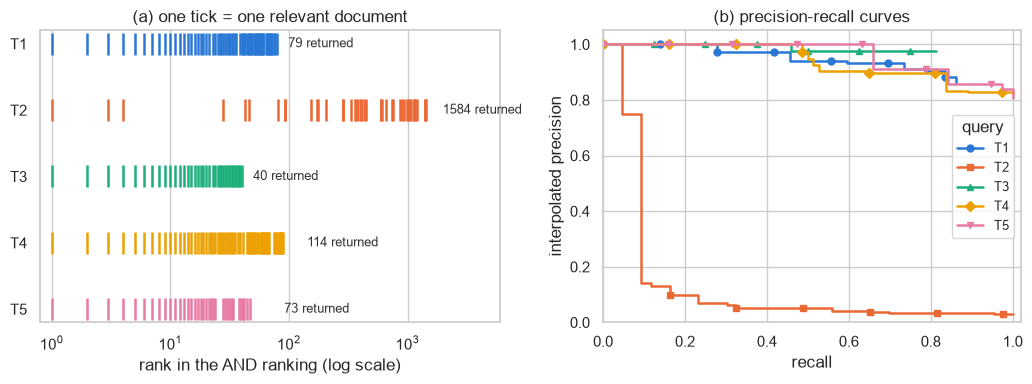

In [29]:
# Figure 2: (a) positions of the relevant documents in the AND ranking, (b) interpolated precision-recall curves
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
markers = ["o", "s", "^", "D", "v"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
for i, (qid, text) in enumerate(TEST_QUERIES.items()):
    rank = {pid: r for r, pid in enumerate(full_run_test[qid], 1)}
    xs = [rank[p] for p in qrels_test[qid] if p in rank]
    ax.scatter(xs, [len(TEST_QUERIES) - i] * len(xs), marker="|", s=260, color=palette[i], linewidths=1.8, zorder=3)
    ax.text(len(full_run_test[qid]) * 1.25, len(TEST_QUERIES) - i, f"{len(full_run_test[qid])} returned", va="center", fontsize=9.5, color="#333")
ax.set_xscale("log")
ax.set(xlim=(0.8, 6000), yticks=range(1, 6), yticklabels=[f"T{q}" for q in reversed(list(TEST_QUERIES))],
       xlabel="rank in the AND ranking (log scale)", title="(a) one tick = one relevant document")
ax.grid(axis="y", visible=False)
ax = axes[1]
for i, (qid, text) in enumerate(TEST_QUERIES.items()):
    r, p = interpolated_pr_curve(full_run_test[qid], set(qrels_test[qid]))
    ax.step([0] + r, [p[0]] + p, where="post", color=palette[i], lw=1.8, label=f"T{qid}", marker=markers[i], markevery=max(len(r) // 6, 1), ms=5)
ax.set(xlim=(0, 1.02), ylim=(0, 1.05), xlabel="recall", ylabel="interpolated precision", title="(b) precision-recall curves")
ax.legend(title="query", fontsize=9.5, loc="center right")
savefig("test_queries_ranking")

## 3.5 Analysis of the results and limitations of the system

The numbers used in the report to support each limitation are computed here. Every experiment changes **one thing** of the
system and is evaluated on the two sets of judgments (validation queries with the condensed-list protocol, and our five queries).

### (a) Ranking function: does a different weighting solve the ranking problems?

In [30]:
def run_queries(eng, min_match=None, rerank_and_first=False):
    # returns (validation runs [condensed], test runs [whole ranking])
    def one(text):
        res = [pid for pid, _ in eng.search(text, min_match=min_match)]
        if rerank_and_first:                                     # AND results first, then the documents that miss one term
            and_res = [pid for pid, _ in eng.search(text)]
            seen = set(and_res)
            res = and_res + [p for p in res if p not in seen]
        return res
    val = {q: condense(one(t), qrels_val[q]) for q, t in VALIDATION_QUERIES.items()}
    test = {q: one(t) for q, t in TEST_QUERIES.items()}
    return val, test

def score_variant(name, val, test):
    tv, tt = evaluate_run(val, qrels_val, (10,)), evaluate_run(test, qrels_test, (10,))
    row = {"variant": name,
           "val MAP": tv.loc["mean", "AP"], "val NDCG@10": tv.loc["mean", "NDCG@10"], "val R@20": evaluate_run(val, qrels_val, (20,)).loc["mean", "R@20"],
           "test MAP": tt.loc["mean", "AP"], "test NDCG@10": tt.loc["mean", "NDCG@10"], "test P@10": tt.loc["mean", "P@10"],
           "test recall (whole list)": float(np.mean([len(set(test[q]) & set(qrels_test[q])) / len(qrels_test[q]) for q in TEST_QUERIES])),
           "test docs returned (mean)": float(np.mean([len(test[q]) for q in TEST_QUERIES]))}
    for q in TEST_QUERIES:
        row[f"AP T{q}"] = tt.loc[q, "AP"]
    return row

experiments = []
base_val, base_test = run_queries(engine)
experiments.append(score_variant("baseline: AND + cosine TF-IDF on the merged field", base_val, base_test))

bm25_engine = SearchEngine(index, pp.preprocess_text, Bm25Ranker(index))
experiments.append(score_variant("BM25 (k1=1.2, b=0.75) on the merged field", *run_queries(bm25_engine)))

weights = {"title_terms": 3, "product_details_terms": 2, "brand_terms": 2, "sub_category_terms": 1, "description_terms": 1}
fw_terms = [sum((list(row[f]) * w for f, w in weights.items()), []) for _, row in corpus.iterrows()]
fw_index = InvertedIndex(corpus.pid.tolist(), fw_terms)
fw_engine = SearchEngine(fw_index, pp.preprocess_text)
experiments.append(score_variant("field-weighted TF-IDF (title x3, details x2, brand x2)", *run_queries(fw_engine)))
pd.DataFrame(experiments).round(3).set_index("variant")[["val MAP", "val NDCG@10", "test MAP", "test NDCG@10"]]

,val MAP,val NDCG@10,test MAP,test NDCG@10
variant,,,,
baseline: AND + cosine TF-IDF on the merged field,0.760,0.858,0.723,0.885
"BM25 (k1=1.2, b=0.75) on the merged field",0.772,0.859,0.736,0.817
"field-weighted TF-IDF (title x3, details x2, brand x2)",0.766,0.856,0.727,0.885


### (b) Query semantics: relaxing the AND

In [31]:
n_minus_1 = lambda text: max(len(set(pp.preprocess_text(text))) - 1, 1)
def run_soft(first_and=False):
    def one(text):
        mm = n_minus_1(text)
        soft = [pid for pid, _ in engine.search(text, min_match=mm)]
        if not first_and:
            return soft
        and_res = [pid for pid, _ in engine.search(text)]
        return and_res + [p for p in soft if p not in set(and_res)]
    return ({q: condense(one(t), qrels_val[q]) for q, t in VALIDATION_QUERIES.items()},
            {q: one(t) for q, t in TEST_QUERIES.items()})

experiments.append(score_variant("soft AND (>= n-1 terms), ranked by TF-IDF", *run_soft(first_and=False)))
experiments.append(score_variant("AND results first, then the documents that miss one term", *run_soft(first_and=True)))
pd.DataFrame(experiments).round(3).set_index("variant").iloc[3:][["val MAP", "val R@20", "test MAP", "test recall (whole list)", "test docs returned (mean)"]]

,val MAP,val R@20,test MAP,test recall (whole list),test docs returned (mean)
variant,,,,,
"soft AND (>= n-1 terms), ranked by TF-IDF",0.877,1.0,0.256,1.0,2730.6
"AND results first, then the documents that miss one term",0.890,1.0,0.736,1.0,2730.6


### (c) Indexing decisions of Part 1 that hide information

Two decisions of Part 1 have a visible cost for our queries: the 1-character tokens are removed (`V neck` becomes `neck`) and
from `product_details` only the values are indexed (`Hooded: Yes` becomes the term `yes`). We test the **effect of changing
them** without touching the Part 1 files: the functions of `preprocessing.py` are replaced temporarily (inside this notebook only) by
versions that (1) write `V neck`, `V-neck` as the single term `vneck`, and (2) keep the key name when the value is `Yes`.
The corpus is pre-processed again (~40 s) and queries and documents use the same modified pipeline.

In [32]:
@contextmanager
def whatif_preprocessing():
    original_text, original_flatten = pp.preprocess_text, pp.flatten_product_details
    def text_vneck(text, **kwargs):
        if isinstance(text, str):
            text = re.sub(r"\bv[\s\-]neck(ed)?\b", "vneck", text, flags=re.I)
        return original_text(text, **kwargs)
    def flatten_keep_yes_keys(details, include_keys=False):
        parts = []
        for key, value in pp.details_to_dict(details).items():
            if key in pp.EXCLUDED_DETAIL_KEYS or value is None or str(value).strip() == "":
                continue
            parts.append(f"{key} {value}" if str(value).strip().lower() == "yes" else str(value))
        return ". ".join(parts)
    pp.preprocess_text, pp.flatten_product_details = text_vneck, flatten_keep_yes_keys
    try:
        yield text_vneck
    finally:
        pp.preprocess_text, pp.flatten_product_details = original_text, original_flatten      # Part 1 functions restored

t0 = time.time()
with whatif_preprocessing() as whatif_text:
    corpus_w = pp.preprocess_corpus(raw)
print(f"modified corpus ready in {time.time() - t0:.0f} s | Part 1 functions restored:",
      pp.preprocess_text.__name__ == "preprocess_text" and pp.flatten_product_details.__name__ == "flatten_product_details")
index_w = InvertedIndex(corpus_w.pid.tolist(), corpus_w.all_terms.tolist())
engine_w = SearchEngine(index_w, whatif_text)
assert corpus.pid.tolist() == corpus_w.pid.tolist()
experiments.append(score_variant("what-if pre-processing: 'vneck' term + keys of 'Yes' details", *run_queries(engine_w)))
for qid in (2, 3):
    ret = [pid for pid, _ in engine_w.search(TEST_QUERIES[qid])]
    print(f"T{qid}: AND matches {len(full_run_test[qid])} -> {len(ret)} | relevant returned "
          f"{len(set(full_run_test[qid]) & set(qrels_test[qid]))} -> {len(set(ret) & set(qrels_test[qid]))} of {len(qrels_test[qid])}")

modified corpus ready in 90 s | Part 1 functions restored: True
T2: AND matches 1584 -> 69 | relevant returned 43 -> 43 of 43
T3: AND matches 40 -> 49 | relevant returned 39 -> 48 of 48


In [33]:
experiments_df = pd.DataFrame(experiments).set_index("variant")
experiments_df.round(3).to_csv(os.path.join(RES_DIR, "experiments.csv"))
experiments_df.round(3)[["val MAP", "val NDCG@10", "val R@20", "test MAP", "test NDCG@10", "test P@10", "test recall (whole list)", "test docs returned (mean)"]]

,val MAP,val NDCG@10,val R@20,test MAP,test NDCG@10,test P@10,test recall (whole list),test docs returned (mean)
variant,,,,,,,,
baseline: AND + cosine TF-IDF on the merged field,0.760,0.858,0.8,0.723,0.885,0.86,0.935,378.0
"BM25 (k1=1.2, b=0.75) on the merged field",0.772,0.859,0.8,0.736,0.817,0.82,0.935,378.0
"field-weighted TF-IDF (title x3, details x2, brand x2)",0.766,0.856,0.8,0.727,0.885,0.86,0.935,378.0
"soft AND (>= n-1 terms), ranked by TF-IDF",0.877,0.886,1.0,0.256,0.429,0.40,1.000,2730.6
"AND results first, then the documents that miss one term",0.890,0.890,1.0,0.736,0.885,0.86,1.000,2730.6
what-if pre-processing: 'vneck' term + keys of 'Yes' details,0.754,0.856,0.8,0.923,1.000,1.00,0.972,76.8


In [34]:
experiments_df.round(3)[[c for c in experiments_df.columns if c.startswith("AP T")]]

,AP T1,AP T2,AP T3,AP T4,AP T5
variant,,,,,
baseline: AND + cosine TF-IDF on the merged field,0.821,0.106,0.800,0.933,0.953
"BM25 (k1=1.2, b=0.75) on the merged field",0.839,0.083,0.804,0.956,0.996
"field-weighted TF-IDF (title x3, details x2, brand x2)",0.823,0.105,0.801,0.943,0.963
"soft AND (>= n-1 terms), ranked by TF-IDF",0.309,0.087,0.186,0.277,0.419
"AND results first, then the documents that miss one term",0.864,0.106,0.826,0.933,0.953
what-if pre-processing: 'vneck' term + keys of 'Yes' details,0.821,0.918,0.987,0.935,0.953


### (d) Other observations used in the analysis

In [35]:
# vocabulary problems that no AND query can solve (stems of equivalent words / spelling variants)
checks = {"hoodie / hooded": ["hoodie", "hooded"], "gray / grey": ["gray", "grey"], "leggings / legging": ["leggings", "legging"],
          "polycotton / polyester": ["polycotton", "polyester"], "trousers / pants": ["trousers", "pants"],
          "V neck": ["v neck"], "sweater / pullover": ["sweater", "pullover"]}
rows = []
for label, words in checks.items():
    for w in words:
        stem = pp.preprocess_text(w)
        rows.append({"group": label, "word": w, "after pre-processing": " ".join(stem) if stem else "(removed)",
                     "documents": index.document_frequency(stem[0]) if stem else 0})
vocab_checks = pd.DataFrame(rows)
vocab_checks.to_csv(os.path.join(RES_DIR, "vocabulary_checks.csv"), index=False)
vocab_checks

,group,word,after pre-processing,documents
0,hoodie / hooded,hoodie,hoodi,634
1,hoodie / hooded,hooded,hood,920
2,gray / grey,gray,gray,57
3,gray / grey,grey,grey,3046
4,leggings / legging,leggings,leg,120
5,leggings / legging,legging,leg,120
6,polycotton / polyester,polycotton,polycotton,2803
7,polycotton / polyester,polyester,polyest,3033
8,trousers / pants,trousers,trouser,1929
9,trousers / pants,pants,pant,2028


In [36]:
# ignored signals: stock and rating of the results (top 20 of every test query)
top20 = [pid for q in TEST_QUERIES for pid in full_run_test[q][:20]]
meta = corpus.set_index("pid")
print("out of stock among the top-20 results of the 5 test queries: %d / %d" % (meta.loc[top20, "out_of_stock"].sum(), len(top20)))
print("out of stock in the whole collection: %.1f%%" % (100 * corpus.out_of_stock.mean()))
# near-duplicates: distinct (title, brand) among the top-10 of every test query
for q in TEST_QUERIES:
    top10 = full_run_test[q][:10]
    print(f"T{q}: distinct titles in the top-10: {meta.loc[top10, 'title'].nunique()} | distinct brands: {meta.loc[top10, 'brand'].nunique()}")

out of stock among the top-20 results of the 5 test queries: 13 / 100
out of stock in the whole collection: 5.9%
T1: distinct titles in the top-10: 1 | distinct brands: 4
T2: distinct titles in the top-10: 5 | distinct brands: 6
T3: distinct titles in the top-10: 4 | distinct brands: 8
T4: distinct titles in the top-10: 2 | distinct brands: 3
T5: distinct titles in the top-10: 3 | distinct brands: 4


In [37]:
# brand completion of Part 1 (the brand is truncated in the data): how many Reebok products say 'reebok' in their own text?
is_reebok = corpus.brand_full.fillna("").str.startswith("reebok")
own_text = corpus.title_terms + corpus.description_terms + corpus.product_details_terms
says_reebok = own_text.map(lambda terms: "reebok" in terms)
print("raw brand values of the Reebok products:", sorted(corpus[is_reebok].brand.unique()))
print("Reebok products (completed brand):", int(is_reebok.sum()),
      "| their title / description / details mention 'reebok':", int((is_reebok & says_reebok).sum()),
      "| found only thanks to the completed brand:", int((is_reebok & ~says_reebok).sum()))

raw brand values of the Reebok products: ['REEB', 'REEBOK CLASSI']
Reebok products (completed brand): 877 | their title / description / details mention 'reebok': 193 | found only thanks to the completed brand: 684


In [38]:
# facts quoted in the report
unreturned = {}
for q, text in VALIDATION_QUERIES.items():
    terms = list(dict.fromkeys(pp.preprocess_text(text)))
    for pid, lab in qrels_val[q].items():
        if pid not in set(full_run_val[q]):
            missing = [t for t in terms if t not in set(corpus.set_index("pid").loc[pid, "all_terms"])]
            unreturned.setdefault(f"Q{q}", []).append({"pid": pid, "label": int(lab), "missing": missing, "title": corpus.set_index("pid").loc[pid, "title"]})
and1 = full_run_val[1]
observations = {
    "index": {k: (float(v) if isinstance(v, (np.floating, float)) else int(v)) for k, v in index_stats.items()},
    "val_unreturned": unreturned,
    "val_unreturned_missing_terms": {q: dict(Counter(t for d in docs for t in d["missing"])) for q, docs in unreturned.items()},
    "val1_len_judged": float(len_all[list(qrels_val[1])].mean()), "val1_len_and": float(len_all[and1].mean()),
    "val1_len_top10": float(len_all[and1[:10]].mean()),
    "val1_rank_min": int(min(and1.index(p) + 1 for p in qrels_val[1])), "val1_rank_max": int(max(and1.index(p) + 1 for p in qrels_val[1])),
    "out_of_stock_top20": int(meta.loc[top20, "out_of_stock"].sum()), "top20_total": len(top20),
    "out_of_stock_rate_collection": float(corpus.out_of_stock.mean()),
    "distinct_titles_top10": {f"T{q}": int(meta.loc[full_run_test[q][:10], "title"].nunique()) for q in TEST_QUERIES},
    "distinct_brands_top10": {f"T{q}": int(meta.loc[full_run_test[q][:10], "brand"].nunique()) for q in TEST_QUERIES},
    "reebok_total": int(is_reebok.sum()), "reebok_in_text": int((is_reebok & says_reebok).sum()),
    "reebok_only_completed": int((is_reebok & ~says_reebok).sum()),
    "whatif": {f"T{q}": {"and_before": len(full_run_test[q]), "and_after": len(engine_w.search(TEST_QUERIES[q])),
                         "relevant_returned_before": len(set(full_run_test[q]) & set(qrels_test[q])),
                         "relevant_returned_after": len({p for p, _ in engine_w.search(TEST_QUERIES[q])} & set(qrels_test[q])),
                         "R": len(qrels_test[q])} for q in TEST_QUERIES},
}
with open(os.path.join(RES_DIR, "summary.json"), "w") as f:
    json.dump(observations, f, indent=1)
print("results written to", RES_DIR)
print({k: v for k, v in observations.items() if k.startswith("val_unreturned_missing") or k.startswith("out_of")})

results written to c:\Github\irwa-search-engine\project_progress\part_2\results
{'val_unreturned_missing_terms': {'Q2': {'men': 11, 'slim': 1}}, 'out_of_stock_top20': 13, 'out_of_stock_rate_collection': 0.05854700854700855}


# 4. Summary

1. **Index.** Inverted index on the merged field of Part 1 (28,080 documents, 5,865 terms), AND retrieval by merging sorted
   postings, TF-IDF cosine ranking. Checked against brute-force implementations.
2. **Metrics.** P@K, R@K, F1@K, AP@K, MAP, MRR and NDCG@K, checked against hand-computed values and scikit-learn.
3. **Validation queries.** Reported with the condensed-list protocol (judged documents only, in the order of the system).
4. **Own judgments.** Five queries, every document of the collection labelled with explicit guidelines (`relevance_judgments.csv`).
5. **Limitations.** The weighting function matters little; what is **indexed** matters a lot (what-if experiment), and AND
   loses relevant documents when query and document use different words. See the report for the proposals.